# 03 · H1: Does LLM exposure rise with skill?

**H1.** Job Zone 4–5 occupations are more exposed to large language models than Job Zone 1–3 occupations.

*Governance argument tested:* the omni-use character of current AI extends automation into cognitive, creative and professional work (Suleyman 2023).
*Brynjolfsson–McAfee prediction:* the earlier wave displaced routine middle-skill work (*Second Machine Age* Ch. 9). Machine learning reaches a different set of occupations (Brynjolfsson, Mitchell & Rock 2018), and higher-income jobs are more exposed (Eloundou et al. 2024).

Cross-section of occupations in May 2022, weighted by employment. Exposure = Eloundou β (E1 + 0.5·E2).

In [1]:
from rwm_common import *
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
set_style()
cross = pd.read_csv(DATA_FIN / "occ_cross.csv", dtype={"soc": str})
cross = cross.dropna(subset=["beta_gpt", "job_zone_cat", "tot_emp"]).copy()
cross["job_zone_cat"] = cross["job_zone_cat"].astype(int)
cross["high_skill"] = (cross["job_zone_cat"] >= 4).astype(int)
print(len(cross), "occupations;", f"{cross['tot_emp'].sum()/1e6:.1f}m workers")

771 occupations; 137.2m workers


## Table 1. Exposure by Job Zone

In [2]:
def wmean(g, c):
    return np.average(g[c], weights=g["tot_emp"])

t1 = cross.groupby("job_zone_cat").apply(lambda g: pd.Series({
    "occupations": len(g),
    "employment_m": g["tot_emp"].sum() / 1e6,
    "emp_share_pct": 100 * g["tot_emp"].sum() / cross["tot_emp"].sum(),
    "median_wage_usd": wmean(g.dropna(subset=["a_median"]), "a_median"),
    "beta_gpt": wmean(g, "beta_gpt"),
    "beta_human": wmean(g.dropna(subset=["beta_human"]), "beta_human"),
    "alpha_gpt": wmean(g, "alpha_gpt"),
    "gamma_gpt": wmean(g, "gamma_gpt"),
}), include_groups=False)
t1.index.name = "Job Zone"
save_table(t1, "table1_exposure_by_job_zone", "LLM exposure by O*NET Job Zone (employment-weighted, May 2022)")
t1.round(3)

Saved table table1_exposure_by_job_zone


,occupations,employment_m,emp_share_pct,median_wage_usd,beta_gpt,beta_human,alpha_gpt,gamma_gpt
Job Zone,,,,,,,,
1,31.0,8.566,6.242,30361.824,0.068,0.090,0.040,0.096
2,281.0,57.016,41.549,38625.824,0.294,0.276,0.151,0.436
3,174.0,27.549,20.075,51759.724,0.328,0.258,0.158,0.498
4,163.0,36.943,26.921,86589.723,0.508,0.457,0.161,0.855
5,122.0,7.153,5.212,107928.612,0.421,0.407,0.099,0.743


## Table 2. Exposure regressions

In [3]:
specs = {
    "(1) Job Zone, GPT-4": ("beta_gpt ~ C(job_zone_cat)", "beta_gpt"),
    "(2) Job Zone, human": ("beta_human ~ C(job_zone_cat)", "beta_human"),
    "(3) High skill, GPT-4": ("beta_gpt ~ high_skill", "beta_gpt"),
    "(4) Log median wage, GPT-4": ("beta_gpt ~ lmed", "beta_gpt"),
    "(5) Log wage + Job Zone": ("beta_gpt ~ lmed + C(job_zone_cat)", "beta_gpt"),
}
rows, fits = [], {}
for lab, (f, y) in specs.items():
    d = cross.dropna(subset=[y, "lmed"])
    r = smf.wls(f, data=d, weights=d["tot_emp"]).fit(cov_type="HC1")
    fits[lab] = r
    for n in r.params.index:
        if n == "Intercept":
            continue
        rows.append({"model": lab, "term": n, "coef": r.params[n], "se": r.bse[n],
                     "p": r.pvalues[n], "r2": r.rsquared, "n": int(r.nobs)})
t2 = pd.DataFrame(rows).set_index(["model", "term"])
save_table(t2, "table2_h1_regressions", "Exposure on skill level (WLS, employment weights, HC1 SEs)")
t2.round(4)

Saved table table2_h1_regressions


coef      se       p  \
model                      term                                           
(1) Job Zone, GPT-4        C(job_zone_cat)[T.2]  0.2258  0.0365  0.0000   
                           C(job_zone_cat)[T.3]  0.2601  0.0485  0.0000   
                           C(job_zone_cat)[T.4]  0.4398  0.0294  0.0000   
                           C(job_zone_cat)[T.5]  0.3539  0.0232  0.0000   
(2) Job Zone, human        C(job_zone_cat)[T.2]  0.1858  0.0395  0.0000   
                           C(job_zone_cat)[T.3]  0.1684  0.0385  0.0000   
                           C(job_zone_cat)[T.4]  0.3677  0.0288  0.0000   
                           C(job_zone_cat)[T.5]  0.3190  0.0265  0.0000   
(3) High skill, GPT-4      high_skill            0.2110  0.0314  0.0000   
(4) Log median wage, GPT-4 lmed                  0.2400  0.0305  0.0000   
(5) Log wage + Job Zone    C(job_zone_cat)[T.2]  0.1902  0.0390  0.0000   
                           C(job_zone_cat)[T.3]  0.1807  0.0594  0.0024   
                           C(job_zone_cat)[T.4]  0.2819  0.0528  0.0000   
                           C(job_zone_cat)[T.5]  0.1669  0.0622  0.0073   
                           lmed                  0.1567  0.0469  0.0008   

                                                     r2    n  
model                      term                               
(1) Job Zone, GPT-4        C(job_zone_cat)[T.2]  0.2715  757  
                           C(job_zone_cat)[T.3]  0.2715  757  
                           C(job_zone_cat)[T.4]  0.2715  757  
                           C(job_zone_cat)[T.5]  0.2715  757  
(2) Job Zone, human        C(job_zone_cat)[T.2]  0.2619  757  
                           C(job_zone_cat)[T.3]  0.2619  757  
                           C(job_zone_cat)[T.4]  0.2619  757  
                           C(job_zone_cat)[T.5]  0.2619  757  
(3) High skill, GPT-4      high_skill            0.1970  757  
(4) Log median wage, GPT-4 lmed                  0.2442  757  
(5) Log wage + Job Zone    C(job_zone_cat)[T.2]  0.3057  757  
                           C(job_zone_cat)[T.3]  0.3057  757  
                           C(job_zone_cat)[T.4]  0.3057  757  
                           C(job_zone_cat)[T.5]  0.3057  757  
                           lmed                  0.3057  757

## Figure 1. Exposure by Job Zone and by wage decile

Saved figure fig1_exposure_by_skill


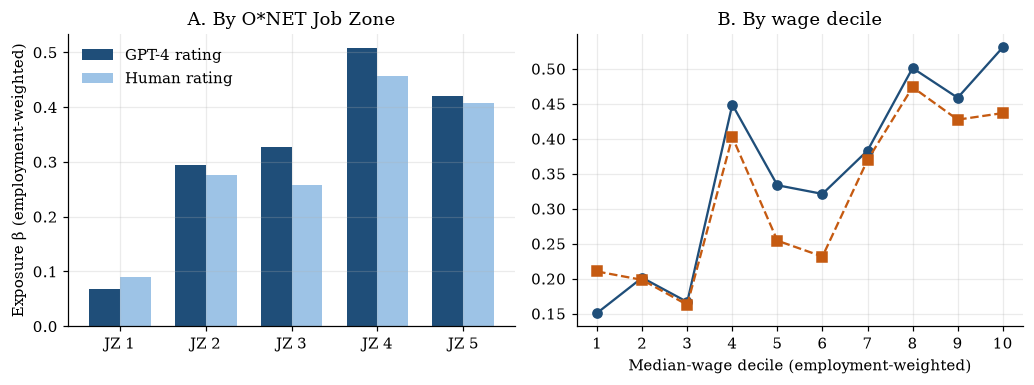

,gpt,human
wage_decile,,
1.0,0.151,0.210
2.0,0.201,0.198
3.0,0.167,0.163
4.0,0.449,0.403
5.0,0.334,0.254
6.0,0.321,0.232
7.0,0.383,0.369
8.0,0.501,0.474
9.0,0.459,0.427


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
ax = axes[0]
x = np.arange(len(t1))
ax.bar(x - 0.18, t1["beta_gpt"], 0.36, color=PALETTE["main"], label="GPT-4 rating")
ax.bar(x + 0.18, t1["beta_human"], 0.36, color=PALETTE["light"], label="Human rating")
ax.set_xticks(x, [f"JZ {i}" for i in t1.index])
ax.set_ylabel("Exposure β (employment-weighted)")
ax.set_title("A. By O*NET Job Zone")
ax.legend()

cross["wage_decile"] = weighted_quantile_bins(cross["a_median"], cross["tot_emp"], 10)
dec = cross.dropna(subset=["wage_decile"]).groupby("wage_decile").apply(
    lambda g: pd.Series({"gpt": wmean(g, "beta_gpt"),
                         "human": wmean(g.dropna(subset=["beta_human"]), "beta_human")}),
    include_groups=False)
ax = axes[1]
ax.plot(dec.index, dec["gpt"], "o-", color=PALETTE["main"], label="GPT-4 rating")
ax.plot(dec.index, dec["human"], "s--", color=PALETTE["alt"], label="Human rating")
ax.set_xticks(range(1, 11))
ax.set_xlabel("Median-wage decile (employment-weighted)")
ax.set_title("B. By wage decile")
fig.tight_layout()
save_fig(fig, "fig1_exposure_by_skill")
plt.show()
dec.round(3)

## Table 3. Highly skilled, highly exposed professions

The 20 largest Job Zone 4–5 occupations in the top exposure quartile. These examples carry the qualitative discussion in the paper.

In [5]:
q75 = np.quantile(cross["beta_gpt"], 0.75)
t3 = (cross[(cross["high_skill"] == 1) & (cross["beta_gpt"] >= q75)]
      .sort_values("tot_emp", ascending=False)
      .head(20)[["soc", "occ_title", "job_zone_cat", "tot_emp", "a_median", "beta_gpt", "beta_human", "protective_idx"]]
      .set_index("soc"))
save_table(t3, "table3_exposed_professions", "Largest highly skilled occupations in the top exposure quartile (May 2022)")
t3.round(3)

Saved table table3_exposed_professions


,occ_title,job_zone_cat,tot_emp,a_median,beta_gpt,beta_human,protective_idx
soc,,,,,,,
15-1252,Software Developers,4,1534790.0,127260.0,0.868,0.447,-0.973
13-2011,Accountants and Auditors,4,1402420.0,78000.0,0.560,0.520,0.711
41-4012,"Sales Representatives, Wholesale and Manufactu...",4,1273400.0,63230.0,0.621,0.707,0.626
13-1199,"Business Operations Specialists, All Other",4,1081230.0,75990.0,0.583,0.538,0.826
13-1082,Project Management Specialists,4,843910.0,95370.0,0.550,0.400,NaN
13-1071,Human Resources Specialists,4,835360.0,64240.0,0.644,0.589,0.654
13-1161,Market Research Analysts and Marketing Special...,4,798620.0,68230.0,0.525,0.543,0.244
11-3021,Computer and Information Systems Managers,4,533220.0,164070.0,0.530,0.561,1.589
15-1211,Computer Systems Analysts,4,505210.0,102240.0,0.617,0.553,0.536


## Exposure and the human skills the books say machines lack

In [6]:
cm = cross[["beta_gpt", "social_idx", "sync_idx", "ideation_idx", "protective_idx", "lmed", "job_zone"]].corr(method="spearman")
save_table(cm, "table_s1_exposure_skill_correlations", "Spearman correlations between exposure and skill indices")
cm.round(2)

Saved table table_s1_exposure_skill_correlations


,beta_gpt,social_idx,sync_idx,ideation_idx,protective_idx,lmed,job_zone
beta_gpt,1.00,0.50,0.17,0.47,0.38,0.47,0.60
social_idx,0.50,1.00,0.66,0.66,0.91,0.50,0.62
sync_idx,0.17,0.66,1.00,0.57,0.90,0.33,0.34
ideation_idx,0.47,0.66,0.57,1.00,0.67,0.72,0.77
protective_idx,0.38,0.91,0.90,0.67,1.00,0.46,0.53
lmed,0.47,0.50,0.33,0.72,0.46,1.00,0.73
job_zone,0.60,0.62,0.34,0.77,0.53,0.73,1.00


## Verdict and numbers for the paper

In [7]:
jz = t1["beta_gpt"]
r3 = fits["(3) High skill, GPT-4"]
res = {
    "n_occupations": int(len(cross)),
    "employment_m": round(cross["tot_emp"].sum() / 1e6, 1),
    "beta_by_jobzone": jz.round(4).to_dict(),
    "high_minus_low_beta": round(float(r3.params["high_skill"]), 4),
    "high_minus_low_p": float(r3.pvalues["high_skill"]),
    "beta_per_log_wage": round(float(fits["(4) Log median wage, GPT-4"].params["lmed"]), 4),
    "spearman_gpt_human": round(float(cross["beta_gpt"].corr(cross["beta_human"], method="spearman")), 3),
    "verdict": "supported" if (r3.params["high_skill"] > 0 and r3.pvalues["high_skill"] < 0.05) else "not supported",
}
(DATA_FIN / "results_h1.json").write_text(json.dumps(res, indent=2, default=str))
print(json.dumps(res, indent=2, default=str))

{
  "n_occupations": 771,
  "employment_m": 137.2,
  "beta_by_jobzone": {
    "1": 0.068,
    "2": 0.2937,
    "3": 0.328,
    "4": 0.5078,
    "5": 0.4207
  },
  "high_minus_low_beta": 0.211,
  "high_minus_low_p": 1.7297729233567647e-11,
  "beta_per_log_wage": 0.24,
  "spearman_gpt_human": 0.909,
  "verdict": "supported"
}
